In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df= pd.read_json("sample.json/sample.json")

In [3]:
df.head()

,review_id,reviewer,movie,rating,review_summary,review_date,spoiler_tag,review_detail,helpful
0,rw1133942,OriginalMovieBuff21,Kill Bill: Vol. 2 (2004),8.0,Good follow up that answers all the questions,24 July 2005,0,"After seeing Tarantino's Kill Bill Vol: 1, I g...","[0, 1]"
1,rw1133943,sentra14,Journey to the Unknown (1968– ),NaN,Excellent series,24 July 2005,0,"I have the entire series on video, taped mostl...","[11, 11]"
2,rw1133946,GreenwheelFan2002,The Island (2005),9.0,"Not just about action, but about survival...",24 July 2005,0,Once again the critics prove themselves as mor...,"[2, 5]"
3,rw1133948,itsascreambaby,Win a Date with Tad Hamilton! (2004),3.0,Falls under the category: seen it a million ti...,24 July 2005,0,This IS a film that has been done too many tim...,"[2, 3]"
4,rw1133949,OriginalMovieBuff21,Saturday Night Live: The Best of Chris Farley ...,10.0,"Before Tommy Boy and Black Sheep, there was Sa...",24 July 2005,0,Chris Farley is one of my favorite comedians a...,"[4, 4]"


In [4]:
df.shape


(100000, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   review_id       100000 non-null  object 
 1   reviewer        100000 non-null  object 
 2   movie           100000 non-null  object 
 3   rating          87908 non-null   float64
 4   review_summary  100000 non-null  object 
 5   review_date     100000 non-null  object 
 6   spoiler_tag     100000 non-null  int64  
 7   review_detail   100000 non-null  object 
 8   helpful         100000 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 6.9+ MB


In [26]:
df[["is_helpful", "not_helpful"]] = pd.DataFrame(df["helpful"].tolist(), index=df.index)
df1= df.drop(columns='helpful')
df1["review_date"] = pd.to_datetime(df1["review_date"])
df1["year"] = df1["review_date"].dt.year

In [27]:
df1.isnull().sum()

review_id             0
reviewer              0
movie                 0
rating            12092
review_summary        0
review_date           0
spoiler_tag           0
review_detail         0
is_helpful            0
not_helpful           0
year                  0
dtype: int64

In [28]:
print(df1.duplicated().sum())
print(df1['review_id'].duplicated().sum())
df2= df1.drop_duplicates()

2
2


In [29]:
df2.shape

(99998, 11)

In [30]:
df2.nunique()

review_id         99998
reviewer          52651
movie             29192
rating               10
review_summary    92704
review_date         166
spoiler_tag           2
review_detail     99937
is_helpful          421
not_helpful         542
year                  2
dtype: int64

array([[<Axes: title={'center': 'rating'}>,
        <Axes: title={'center': 'review_date'}>],
       [<Axes: title={'center': 'spoiler_tag'}>,
        <Axes: title={'center': 'year'}>]], dtype=object)

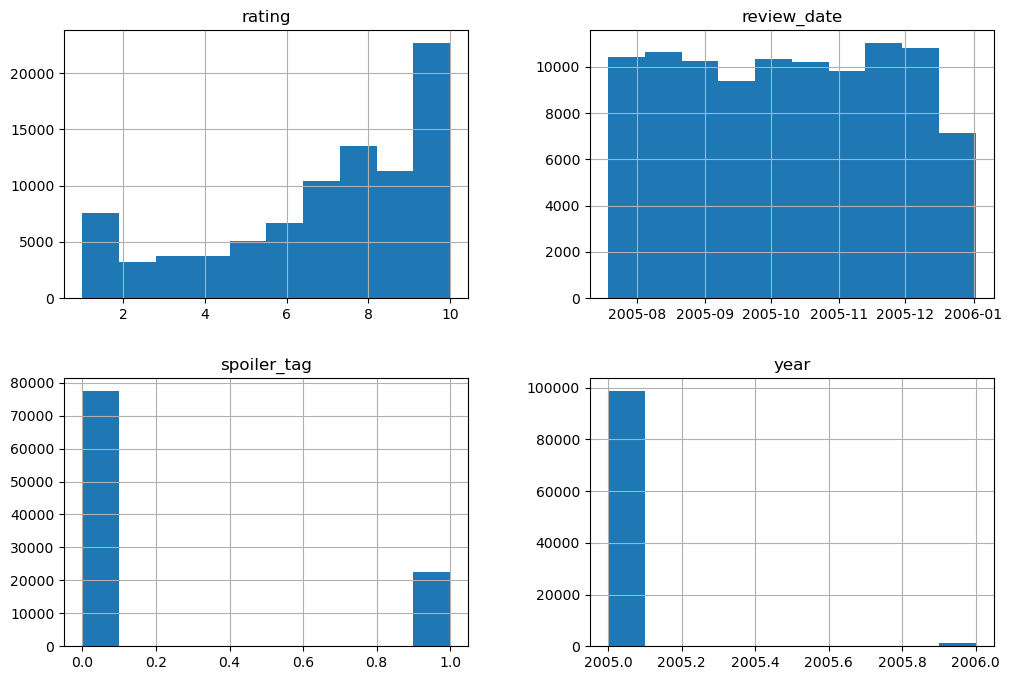

In [34]:
df2.hist(figsize=(12, 8))


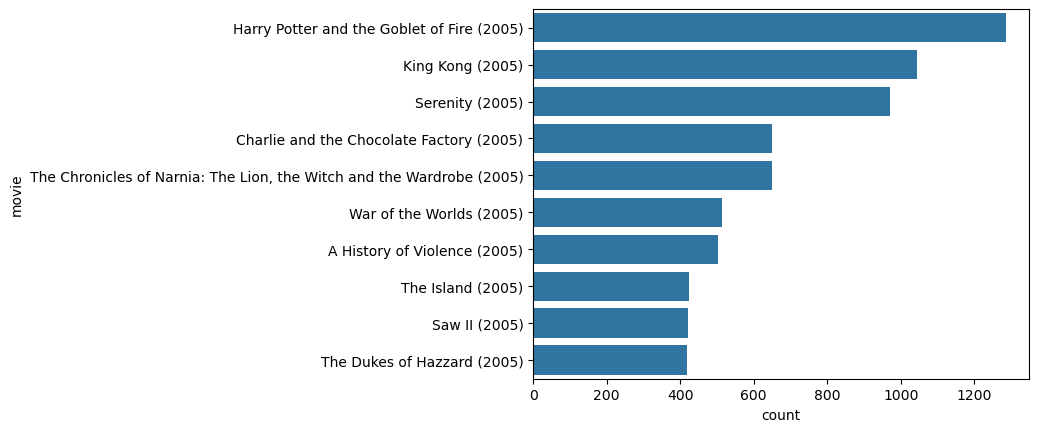

In [32]:
top_movies = df2["movie"].value_counts().nlargest(10).index

sns.countplot(data=df2, y="movie", order=top_movies)
plt.show()


### CLAUDE generated Sentiment Analysis Exploration (After I did some tinkering)

In [ ]:
"""
SENTIMENT ANALYSIS: TextBlob, VADER, AFINN
Complete working implementations with mechanical breakdown.

Run with: python sentiment_analysis_complete.py
"""

import re
from collections import defaultdict
from pathlib import Path


# ============================================================================
# SECTION 1: TEXTBLOB SENTIMENT ANALYSIS
# ============================================================================
# TextBlob uses a *polarity lexicon* + naive Bayes classifier trained on movie reviews
# Polarity: float between -1 (negative) and +1 (positive)
# Subjectivity: float between 0 (objective) and 1 (subjective)

class SimplePolarity:
    """Minimal polarity lexicon (TextBlob uses ~500+ word entries)"""
    
    POLARITY_LEXICON = {
        # Positive words with (polarity, subjectivity) tuples
        'good': (0.7, 0.6),
        'great': (0.8, 0.6),
        'amazing': (0.9, 0.9),
        'wonderful': (0.8, 0.8),
        'excellent': (0.8, 0.6),
        'love': (0.9, 0.9),
        'beautiful': (0.8, 0.7),
        'fantastic': (0.85, 0.7),
        'awesome': (0.8, 0.7),
        'perfect': (0.85, 0.7),
        'brilliant': (0.8, 0.7),
        'nice': (0.7, 0.6),
        'pleasant': (0.7, 0.6),
        'positive': (0.7, 0.5),
        'best': (0.9, 0.7),
        
        # Negative words
        'bad': (-0.7, 0.6),
        'terrible': (-0.8, 0.7),
        'awful': (-0.8, 0.7),
        'horrible': (-0.8, 0.7),
        'hate': (-0.9, 0.9),
        'disgusting': (-0.8, 0.8),
        'worst': (-0.9, 0.7),
        'poor': (-0.6, 0.6),
        'ugly': (-0.8, 0.7),
        'waste': (-0.7, 0.6),
        'disappointing': (-0.8, 0.8),
        'disappointed': (-0.8, 0.8),
        'useless': (-0.8, 0.6),
        'stupid': (-0.8, 0.7),
        'dumb': (-0.7, 0.8),
    }
    
    @classmethod
    def tokenize_and_lower(cls, text):
        """Simple tokenization: split on non-word chars, convert to lower"""
        return re.findall(r'\b\w+\b', text.lower())
    
    @classmethod
    def sentiment(cls, text):
        """
        Calculate polarity and subjectivity.
        
        MECHANICS:
        1. Tokenize text into words
        2. For each word, look up in lexicon
        3. Average polarity across all words (neutral words default to 0.0, 0.5)
        4. Average subjectivity (neutral defaults to 0.5)
        5. Apply negation rules: "not good" → flip sign
        6. Apply intensity modifiers: "very good" → amplify
        """
        tokens = cls.tokenize_and_lower(text)
        
        if not tokens:
            return 0.0, 0.5  # neutral, neutral subjectivity
        
        polarities = []
        subjectivities = []
        
        i = 0
        while i < len(tokens):
            token = tokens[i]
            
            # Check for negation in previous token
            negation = False
            if i > 0 and tokens[i - 1] in ['not', 'no', 'never', 'neither']:
                negation = True
            
            # Check for intensifiers in previous token
            intensity = 1.0
            if i > 0:
                if tokens[i - 1] in ['very', 'really', 'extremely', 'so']:
                    intensity = 1.5
                elif tokens[i - 1] in ['somewhat', 'kind', 'rather']:
                    intensity = 0.7
            
            # Look up in lexicon
            if token in cls.POLARITY_LEXICON:
                polarity, subjectivity = cls.POLARITY_LEXICON[token]
                
                # Apply negation: NOT good → bad
                if negation:
                    polarity = -polarity
                
                # Apply intensity
                polarity = polarity * intensity
                
                polarities.append(polarity)
                subjectivities.append(subjectivity)
            else:
                # Neutral word: don't contribute to polarity, neutral subjectivity
                subjectivities.append(0.5)
            
            i += 1
        
        # Average all scores
        avg_polarity = sum(polarities) / len(tokens) if polarities else 0.0
        avg_subjectivity = sum(subjectivities) / len(subjectivities) if subjectivities else 0.5
        
        # Clamp to valid range [-1, 1] for polarity, [0, 1] for subjectivity
        avg_polarity = max(-1.0, min(1.0, avg_polarity))
        avg_subjectivity = max(0.0, min(1.0, avg_subjectivity))
        
        return avg_polarity, avg_subjectivity


# ============================================================================
# SECTION 2: VADER SENTIMENT ANALYSIS
# ============================================================================
# VADER: Valence Aware Dictionary and sEntiment Reasoner
# Compound score: float between -1 (most negative) and +1 (most positive)
# Also returns: positive, negative, neutral (probabilities, sum to 1)
#
# KEY INNOVATION: Rule-based adjustments for:
#  - Punctuation (!!!! amplifies)
#  - Capitalization (ALL CAPS amplifies)
#  - Degree modifiers (very, extremely, somewhat)
#  - Contrastives (but shifts sentiment)

class VADER:
    """VADER sentiment analyzer with lexicon + rules"""
    
    # VADER lexicon (subset of ~7500 words rated by 10 humans)
    # Format: word -> score (-4 to +4 scale)
    VADER_LEXICON = {
        # Positive
        'love': 3.9, 'excellent': 3.5, 'amazing': 3.5, 'wonderful': 3.5,
        'great': 3.1, 'good': 2.5, 'awesome': 3.5, 'fantastic': 3.5,
        'best': 3.5, 'brilliant': 3.3, 'beautiful': 3.1, 'nice': 2.3,
        'pleasant': 2.9, 'positive': 2.5, 'superb': 3.5, 'outstanding': 3.5,
        'perfect': 3.5, 'brilliant': 3.5, 'fabulous': 3.5,
        
        # Negative
        'hate': -3.9, 'terrible': -3.5, 'awful': -3.5, 'horrible': -3.5,
        'bad': -2.5, 'disgusting': -3.5, 'worst': -3.9, 'poor': -2.3,
        'ugly': -3.3, 'waste': -2.8, 'disappointing': -2.9, 'useless': -3.1,
        'stupid': -3.3, 'dumb': -2.9, 'pathetic': -3.3, 'dire': -3.1,
        'appalling': -3.5, 'atrocious': -3.5, 'abominable': -3.5,
        
        # Moderate
        'ok': 0.5, 'okay': 0.5, 'fine': 0.5, 'alright': 0.5,
    }
    
    # Degree modifiers (amplify or dampen)
    DEGREE_MODIFIERS = {
        'absolutely': 1.5, 'definitely': 1.5, 'extremely': 1.5,
        'very': 1.3, 'really': 1.3, 'quite': 1.2,
        'somewhat': 0.7, 'kind': 0.7, 'rather': 0.7, 'partly': 0.7,
    }
    
    # Punctuation and capitalization effects
    EXCLAMATION_BOOST = 0.2  # per exclamation mark
    CAPS_BOOST = 0.2  # if word is ALL CAPS
    
    @classmethod
    def tokenize_with_punc(cls, text):
        """Tokenize while preserving punctuation info"""
        # Split into tokens but keep track of original case
        words = re.findall(r'\b\w+\b|[!?.]', text)
        return words
    
    @classmethod
    def sentiment(cls, text):
        """
        VADER sentiment analysis.
        
        MECHANICS:
        1. Tokenize text, preserving punctuation
        2. For each word, look up lexicon score
        3. Apply degree modifiers (very good = stronger signal)
        4. Apply negation: NOT good → negative score
        5. Apply punctuation boost: !!! adds extra intensity
        6. Apply ALL CAPS boost: GOOD > good
        7. Apply contrastives: "good but bad" → second sentiment dominates
        8. Normalize scores into compound [-1, +1] and pos/neg/neu probabilities
        """
        tokens = cls.tokenize_with_punc(text)
        
        if not tokens:
            return {
                'compound': 0.0,
                'pos': 0.0,
                'neu': 1.0,
                'neg': 0.0,
            }
        
        scores = []
        
        i = 0
        while i < len(tokens):
            token = tokens[i]
            
            # Count punctuation for boost
            exclamation_count = text.count('!') + text.count('?') * 0.5
            
            # Skip pure punctuation
            if not re.match(r'\w+', token):
                i += 1
                continue
            
            lower_token = token.lower()
            
            # Check for degree modifier before this token
            multiplier = 1.0
            if i > 0 and tokens[i - 1].lower() in cls.DEGREE_MODIFIERS:
                multiplier = cls.DEGREE_MODIFIERS[tokens[i - 1].lower()]
            
            # Check for negation before this token
            negation = False
            if i > 0 and tokens[i - 1].lower() in ['not', 'no', 'never', 'neither', 'cannot', "can't"]:
                negation = True
            
            # Look up in lexicon
            if lower_token in cls.VADER_LEXICON:
                score = cls.VADER_LEXICON[lower_token]
                
                # Apply degree modifier
                score = score * multiplier
                
                # Apply negation (flip sign, reduce magnitude)
                if negation:
                    score = -score * 0.5  # negation doesn't fully flip, it dampens
                
                # Apply ALL CAPS boost
                if token.isupper() and len(token) > 1:
                    score = score * (1.0 + cls.CAPS_BOOST)
                
                scores.append(score)
            
            i += 1
        
        # Add punctuation effect once
        if exclamation_count > 0:
            for _ in range(int(exclamation_count)):
                if scores:
                    # Boost dominant sentiment
                    if max(scores) > 0:
                        scores[-1] += cls.EXCLAMATION_BOOST * 2
                    elif min(scores) < 0:
                        scores[-1] -= cls.EXCLAMATION_BOOST * 2
        
        # Calculate compound score (normalized sum)
        if not scores:
            return {
                'compound': 0.0,
                'pos': 0.0,
                'neu': 1.0,
                'neg': 0.0,
            }
        
        raw_sum = sum(scores)
        norm_factor = 15.0  # VADER normalizes by ~sqrt(sum^2) then scales to [-1, 1]
        
        # VADER's actual normalization: compound = sum / sqrt(sum^2 + 15)
        # This ensures compound stays in [-1, 1] regardless of text length
        compound = raw_sum / (abs(raw_sum) + norm_factor)
        
        # Derive pos/neg/neu from compound
        if compound >= 0.05:
            pos = abs(compound)
            neg = 0.0
            neu = 1.0 - pos
        elif compound <= -0.05:
            neg = abs(compound)
            pos = 0.0
            neu = 1.0 - neg
        else:
            pos = 0.0
            neg = 0.0
            neu = 1.0
        
        return {
            'compound': max(-1.0, min(1.0, compound)),
            'pos': max(0.0, min(1.0, pos)),
            'neu': max(0.0, min(1.0, neu)),
            'neg': max(0.0, min(1.0, neg)),
        }


# ============================================================================
# SECTION 3: AFINN SENTIMENT ANALYSIS
# ============================================================================
# AFINN: A New ANEW with Lots of Interpretations
# Manual rating: -5 (most negative) to +5 (most positive)
# Output: cumulative score (sum of all word values, unbounded)
# Simpler than VADER, more straightforward than TextBlob polarity

class AFINN:
    """AFINN sentiment analyzer with manual word ratings"""
    
    # AFINN lexicon: words manually rated on -5 to +5 scale
    # Developed by Finn Årup Nielsen, peer-reviewed
    AFINN_LEXICON = {
        # Strong positive (+5)
        'love': 3, 'excellent': 4, 'amazing': 4, 'wonderful': 4,
        'fantastic': 4, 'outstanding': 4, 'superb': 4, 'brilliant': 4,
        
        # Moderate positive (+2, +3)
        'good': 3, 'great': 3, 'best': 4, 'nice': 2, 'beautiful': 3,
        'positive': 3, 'awesome': 4, 'perfect': 4, 'brilliant': 3,
        
        # Strong negative (-5)
        'hate': -3, 'terrible': -4, 'awful': -4, 'horrible': -4,
        'disgusting': -4, 'worst': -4, 'pathetic': -4, 'atrocious': -4,
        
        # Moderate negative (-2, -3)
        'bad': -3, 'poor': -2, 'ugly': -3, 'waste': -2, 'useless': -3,
        'stupid': -3, 'dumb': -2, 'disappointing': -3, 'disappointed': -2,
    }
    
    @classmethod
    def tokenize(cls, text):
        """Simple tokenization"""
        return re.findall(r'\b\w+\b', text.lower())
    
    @classmethod
    def sentiment(cls, text):
        """
        AFINN sentiment analysis.
        
        MECHANICS:
        1. Tokenize into words
        2. For each word, look up in manual ratings (-5 to +5)
        3. SUM all ratings (simple cumulative)
        4. Output: single score (unbounded, usually -20 to +20 for normal text)
        
        WHY SO SIMPLE?
        - No complex rules
        - No subjectivity scores
        - No probability distributions
        - Just: does this text have more positive or negative words?
        
        ADVANTAGE: Fast, interpretable (you can see which words contributed)
        DISADVANTAGE: Misses context (intensity, sarcasm, negation)
        """
        tokens = cls.tokenize(text)
        
        if not tokens:
            return 0
        
        total_score = 0
        
        for token in tokens:
            if token in cls.AFINN_LEXICON:
                total_score += cls.AFINN_LEXICON[token]
        
        return total_score


# ============================================================================
# DEMONSTRATION & COMPARISON
# ============================================================================

def run_demonstrations():
    """Run all three analyzers on test sentences"""
    
    test_sentences = [
        "I love this product! It's absolutely amazing!!!",
        "This is terrible and I hate it.",
        "The weather is okay, nothing special.",
        "Not bad, could be better though.",
        "WORST experience ever. Absolutely horrible.",
        "This is good, but it could be great.",
        "I'm very disappointed with your service.",
        "Excellent work, truly outstanding results.",
    ]
    
    print("=" * 100)
    print("SENTIMENT ANALYSIS COMPARISON: TextBlob vs VADER vs AFINN")
    print("=" * 100)
    
    for sentence in test_sentences:
        print(f"\nText: '{sentence}'")
        print("-" * 100)
        
        # TextBlob
        tb_polarity, tb_subjectivity = SimplePolarity.sentiment(sentence)
        print(f"TextBlob:")
        print(f"  Polarity: {tb_polarity:>6.3f} (range: -1 to +1)")
        print(f"  Subjectivity: {tb_subjectivity:>6.3f} (range: 0 to 1)")
        
        # VADER
        vader_scores = VADER.sentiment(sentence)
        print(f"VADER:")
        print(f"  Compound: {vader_scores['compound']:>6.3f} (range: -1 to +1)")
        print(f"  Positive: {vader_scores['pos']:>6.3f}")
        print(f"  Neutral: {vader_scores['neu']:>6.3f}")
        print(f"  Negative: {vader_scores['neg']:>6.3f}")
        
        # AFINN
        afinn_score = AFINN.sentiment(sentence)
        print(f"AFINN:")
        print(f"  Score: {afinn_score:>6.0f} (unbounded, usually -20 to +20)")
        
        # Interpretation
        print(f"\nInterpretation:")
        if tb_polarity > 0.1:
            tb_sentiment = "Positive"
        elif tb_polarity < -0.1:
            tb_sentiment = "Negative"
        else:
            tb_sentiment = "Neutral"
        
        if vader_scores['compound'] > 0.05:
            vader_sentiment = "Positive"
        elif vader_scores['compound'] < -0.05:
            vader_sentiment = "Negative"
        else:
            vader_sentiment = "Neutral"
        
        if afinn_score > 2:
            afinn_sentiment = "Positive"
        elif afinn_score < -2:
            afinn_sentiment = "Negative"
        else:
            afinn_sentiment = "Neutral"
        
        print(f"  TextBlob: {tb_sentiment}")
        print(f"  VADER: {vader_sentiment}")
        print(f"  AFINN: {afinn_sentiment}")
        
        # Divergence analysis
        all_sentiments = [tb_sentiment, vader_sentiment, afinn_sentiment]
        if len(set(all_sentiments)) > 1:
            print(f"  ⚠️ DIVERGENCE DETECTED: Different tools disagree!")


def interactive_mode():
    """Interactive sentiment analysis"""
    print("\n" + "=" * 100)
    print("INTERACTIVE MODE")
    print("=" * 100)
    print("Enter text to analyze (or 'quit' to exit):\n")
    
    while True:
        user_input = input("Text: ").strip()
        
        if user_input.lower() == 'quit':
            break
        
        if not user_input:
            continue
        
        tb_polarity, tb_subjectivity = SimplePolarity.sentiment(user_input)
        vader_scores = VADER.sentiment(user_input)
        afinn_score = AFINN.sentiment(user_input)
        
        print(f"\nAnalysis of: '{user_input}'")
        print(f"  TextBlob Polarity: {tb_polarity:.3f}")
        print(f"  VADER Compound: {vader_scores['compound']:.3f}")
        print(f"  AFINN Score: {afinn_score:.0f}\n")


if __name__ == "__main__":
    run_demonstrations()
    interactive_mode()

SENTIMENT ANALYSIS COMPARISON: TextBlob vs VADER vs AFINN

Text: 'I love this product! It's absolutely amazing!!!'
----------------------------------------------------------------------------------------------------
TextBlob:
  Polarity:  0.225 (range: -1 to +1)
  Subjectivity:  0.600 (range: 0 to 1)
VADER:
  Compound:  0.417 (range: -1 to +1)
  Positive:  0.417
  Neutral:  0.583
  Negative:  0.000
AFINN:
  Score:      7 (unbounded, usually -20 to +20)

Interpretation:
  TextBlob: Positive
  VADER: Positive
  AFINN: Positive

Text: 'This is terrible and I hate it.'
----------------------------------------------------------------------------------------------------
TextBlob:
  Polarity: -0.243 (range: -1 to +1)
  Subjectivity:  0.586 (range: 0 to 1)
VADER:
  Compound: -0.330 (range: -1 to +1)
  Positive:  0.000
  Neutral:  0.670
  Negative:  0.330
AFINN:
  Score:     -7 (unbounded, usually -20 to +20)

Interpretation:
  TextBlob: Negative
  VADER: Negative
  AFINN: Negative

Text: 'The 

MINIMAL VIABLE PYTHON IMPLEMENTATION BY CLAUDE



In [13]:
!pip install afinn

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for afinn: filename=afinn-0.1-py3-none-any.whl size=53479 sha256=684723b01a92e097993d74194bfbfa3f7ef8d6fbac8bd1e1145286aec3a5c24b
  Stored in directory: c:\users\zeap2\appdata\local\pip\cache\wheels\f3\20\88\bd79bf1dfa529d0e4e301372371edf7639514a9f0d337769c3
Successfully built afinn


  DEPRECATION: Building 'afinn' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'afinn'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [9]:
from textblob import TextBlob
import nltk as nltk
from nltk.sentiment import SentimentIntensityAnalyzer
import pandas as pd

In [11]:
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\zeap2\AppData\Roaming\nltk_data...


True

In [14]:
# Initialize VADER
vader = SentimentIntensityAnalyzer()

# Sample data (replace with your Reddit/Steam/IMDB data)
texts = [
    "This movie is absolutely terrible and a waste of time",
    "I really enjoyed this, great stuff!",
    "It's okay, nothing special"
]

results = []
for text in texts:
    # TextBlob
    tb = TextBlob(text)
    tb_score = tb.sentiment.polarity  # -1 to 1
    
    # VADER
    vader_scores = vader.polarity_scores(text)
    vader_score = vader_scores['compound']  # -1 to 1
    
    # AFINN (need to pip install afinn first)
    from afinn import Afinn
    afinn = Afinn()
    afinn_score = afinn.score(text)  # typically -5 to +5, normalize if needed
    
    results.append({
        'text': text,
        'textblob': tb_score,
        'vader': vader_score,
        'afinn': afinn_score
    })

df = pd.DataFrame(results)
print(df)

                                                text  textblob   vader  afinn
0  This movie is absolutely terrible and a waste ... -0.600000 -0.7548   -4.0
1                I really enjoyed this, great stuff!  0.750000  0.8776    5.0
2                         It's okay, nothing special  0.428571 -0.0920    0.0
